#U-Net Image Colorization with Lab Color Space
Groupmembers: Tharushi Kulathunga (IM/2023/064), Praveen Madawalage (IM/2023/081),Sameera Ekanayaka (IM/2023/090),Imasha Karunathilaka (IM/2023/099),
Tharindu Dhanushka (IM/2023/117) ↪

This notebook trains a U-Net auto encoder to predict color(a,b channels in Labspace)
from grayscale(L channel)images, then applies it to a personal black-and-whitephoto.

## 1. Setup and Imports

**Owner: Imasha**

Installs and imports the libraries used throughout the notebook, and checks whether a GPU is available.


In [14]:
!pip install scikit-image -q

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
import numpy as np
from skimage.color import rgb2lab, lab2rgb
import matplotlib.pyplot as plt
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


cuda


## 2. Connect to Google Drive
**Owner: Imasha**

This must run early and every session, before training. It lets the notebook save and resume training progress.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/Team_Colorization_Project', exist_ok=True)
checkpoint_path = '/content/drive/MyDrive/Team_Colorization_Project/checkpoint.pth'
print("Drive connected. Checkpoint will be saved to:", checkpoint_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive connected. Checkpoint will be saved to: /content/drive/MyDrive/Team_Colorization_Project/checkpoint.pth


## 3. Load the Dataset
**Owner: Imasha**

Downloads CIFAR-10, a public dataset of color photos. Only the images are used, not the labels, since the task is colorization, not classification.

In [16]:
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)

## 4. Dataset Class
**Owner: Imasha**

Resizes each image to 128x128, converts it from RGB to Lab color space, and splits it into the L (lightness) channel used as input and the a, b (color) channels used as the training target.

In [17]:
class ColorizationDataset(Dataset):
    def __init__(self, cifar_dataset):
        self.data = cifar_dataset

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, _ = self.data[idx]
        img = img.resize((128, 128))
        img_np = np.array(img) / 255.0

        lab = rgb2lab(img_np).astype("float32")

        L = lab[:, :, 0] / 50.0 - 1.0
        ab = lab[:, :, 1:] / 128.0

        L = torch.from_numpy(L).unsqueeze(0).float()
        ab = torch.from_numpy(ab.transpose(2, 0, 1)).float()

        return L, ab

train_ds = ColorizationDataset(train_set)
test_ds = ColorizationDataset(test_set)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

print("Train images:", len(train_ds))
print("Test images:", len(test_ds))

Train images: 50000
Test images: 10000


## 5. U-Net Model
**Owner: Sameera Ekanayaka**

The encoder shrinks the image while learning its features. The decoder rebuilds it back to full size while predicting color. Skip connections carry fine detail across from encoder to decoder. Input is 1 channel (L), output is 2 channels (predicted a, b).


In [18]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(512, 1024)
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)
        self.out = nn.Conv2d(64, 2, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.tanh(self.out(d1))

model = UNet().to(device)
print(model)


UNet(
  (enc1): DoubleConv(
    (net): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (net): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (net): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3,

In [19]:
test_input = torch.randn(1, 1, 128, 128).to(device)
test_output = model(test_input)
print(test_output.shape)  # Expected: torch.Size([1, 2, 128, 128])

torch.Size([1, 2, 128, 128])


## 6. Training

**Owner: Praveen**

Trains for 15 to 20 epochs using MSE loss and the Adam optimizer. Saves progress to Google Drive after every epoch. If this cell is stopped and run again later, it automatically continues from the last saved epoch instead of starting over.


In [20]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 18
train_losses = []
start_epoch = 0

# 1. Load checkpoint if it exists
if os.path.exists(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(ckpt['model_state'])
    optimizer.load_state_dict(ckpt['optimizer_state'])
    start_epoch = ckpt.get('epoch', 0)
    train_losses = ckpt.get('train_losses', [])
    print(f"Found checkpoint! Loaded up to epoch {start_epoch}/{epochs}.")

# 2. Check if training is already finished
if start_epoch >= epochs:
    print(f"Training already completed ({start_epoch}/{epochs} epochs). Skipping training loop entirely!")
else:
    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        for L, ab in train_loader:
            L, ab = L.to(device), ab.to(device)

            optimizer.zero_grad()
            pred_ab = model(L)
            loss = criterion(pred_ab, ab)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * L.size(0)

        epoch_loss = running_loss / len(train_ds)
        train_losses.append(epoch_loss)
        print(f"Epoch {epoch+1}/{epochs} - MSE loss: {epoch_loss:.5f}")

        # Save checkpoint after every epoch
        torch.save({
            'epoch': epoch + 1,
            'model_state': model.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'train_losses': train_losses,
        }, checkpoint_path)

Found checkpoint! Loaded up to epoch 18/18.
Training already completed (18/18 epochs). Skipping training loop entirely!


## 7. Training Loss Plot
**Owner: Tharushi Kulathunga**

Plots the MSE loss recorded during training. A downward trend shows the model learned.

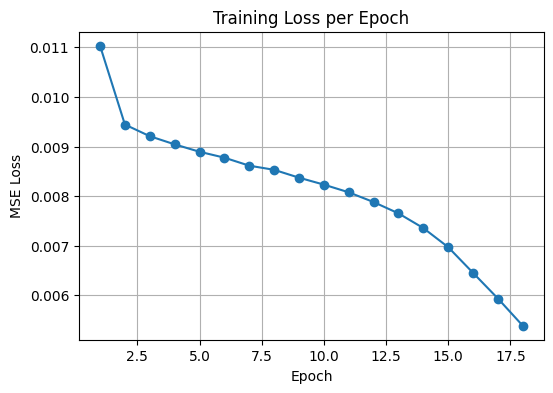

In [21]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss per Epoch")
plt.grid(True)
plt.show()

## 8. Lab to RGB Helper Function
**Owner: Tharushi Kulathunga**

Combines an L channel and predicted a, b channels back into a normal RGB image that can be displayed.

In [22]:
def lab_to_rgb(L_tensor, ab_tensor):
    L = (L_tensor.squeeze(0).cpu().numpy() + 1.0) * 50.0
    ab = ab_tensor.cpu().numpy().transpose(1, 2, 0) * 128.0

    lab = np.zeros((L.shape[0], L.shape[1], 3), dtype="float32")
    lab[:, :, 0] = L
    lab[:, :, 1:] = ab

    rgb = lab2rgb(lab)
    return np.clip(rgb, 0, 1)

## 9. Test on a CIFAR-10 Image
**Owner: Tharushi Kulathunga**

Runs the trained model on an image it has not seen before, to confirm the pipeline works correctly before using the personal photo.

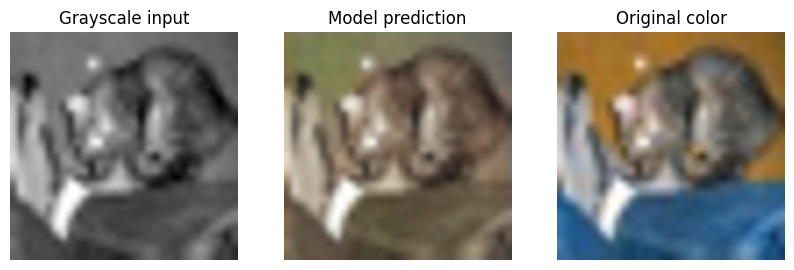

In [23]:
model.eval()
L_test, ab_test = test_ds[0]

with torch.no_grad():
    pred_ab = model(L_test.unsqueeze(0).to(device)).cpu().squeeze(0)

original = lab_to_rgb(L_test, ab_test)
predicted = lab_to_rgb(L_test, pred_ab)

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow((L_test.squeeze(0).numpy() + 1) / 2, cmap="gray")
axes[0].set_title("Grayscale input")
axes[1].imshow(predicted)
axes[1].set_title("Model prediction")
axes[2].imshow(original)
axes[2].set_title("Original color")
for a in axes:
    a.axis("off")
plt.show()

## 10. Upload Personal Photo
**Owner: Tharindu Dhanushka**
Uploads the black-and-white personal photo that the trained model will colorize.


In [24]:
from google.colab import files
uploaded = files.upload()
photo_path = list(uploaded.keys())[0]
print("Uploaded:", photo_path)

Saving Tharucee.jpeg to Tharucee.jpeg
Uploaded: Tharucee.jpeg


## 11. Colorize the Photo
**Owner: Tharindu Dhanushka**
Converts the photo to grayscale, resizes it to 128x128, extracts its L channel, and runs it through the trained model to predict the missing a and b color channels.

In [25]:
from PIL import Image

img = Image.open(photo_path).convert("L")
img = img.resize((128, 128))
gray_np = np.array(img) / 255.0

L_lab = gray_np * 100.0
L_norm = L_lab / 50.0 - 1.0

L_input = torch.from_numpy(L_norm).unsqueeze(0).unsqueeze(0).float().to(device)

model.eval()
with torch.no_grad():
    pred_ab = model(L_input).cpu().squeeze(0)

L_cpu = L_input.cpu().squeeze(0)
restored = lab_to_rgb(L_cpu, pred_ab)

## 12. Final Result
**Owner: Tharindu Dhanushka**
Shows the three required panels: the grayscale input, the model's raw color prediction, and the final restored color image (L channel plus predicted color, recombined).

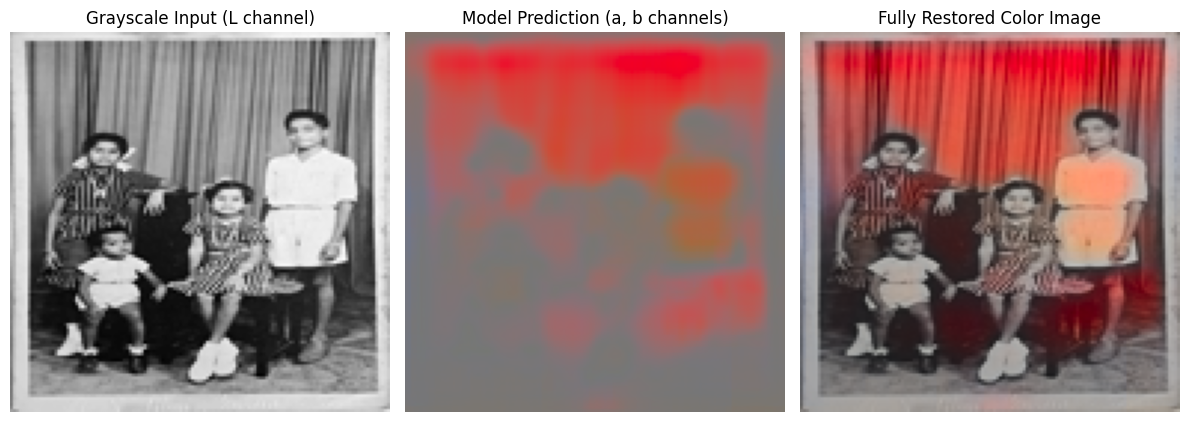

In [26]:
flat_L = torch.zeros_like(L_cpu)
color_only = lab_to_rgb(flat_L, pred_ab)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

axes[0].imshow(gray_np, cmap="gray")
axes[0].set_title("Grayscale Input (L channel)")

axes[1].imshow(color_only)
axes[1].set_title("Model Prediction (a, b channels)")

axes[2].imshow(restored)
axes[2].set_title("Fully Restored Color Image")

for a in axes:
    a.axis("off")

plt.tight_layout()
plt.savefig("colorization_result.png", dpi=150)
plt.show()